# Experiment 1 — Gaussian mixtures: competitiveness in the parametric regime

Figures per `docs/experiments.md`, Experiment 1 "Figures" subsection. This notebook only loads `results/exp1/results.parquet` and plots — it never recomputes algorithm results (see CLAUDE.md and `docs/experiments.md` §0.4). Run `python -m scripts.run_experiment1` (or `SMOKE_TEST=1 python -m scripts.run_experiment1` first) to generate it.

**Note:** this notebook was rewritten as part of Experiment 1's REDESIGN (see `docs/experiments.md`'s Experiment 1 "REDESIGN NOTE"). The old error-rate table, ARI-at-cap, restricted-budget (Fig. 5/5b/5c), and appendix theoretical-vs-calibrated-constants panel are all gone — dropped as part of the redesign, not accidentally omitted. 9 algorithm rows per (grid point, rep): `kabc`, `unif-kkm-1x`, `kabc-0.5x`, `unif-kkm-0.5x`, `kabc-sg`, `kabc-sg-0.5x`, `acb`, `acb-0.5x`, `acb-gaussian` — each `-0.5x` row is its OWN base algorithm re-run at 0.5× that base's own realized τ (a fresh independent RNG draw, not the same pulls truncated early), testing how conservative that algorithm's own stopping rule is; `unif-kkm-1x`/`unif-kkm-0.5x` are tied specifically to `kabc`'s τ. **Multiplier note (2026-09-14):** this was originally 0.9x; changed to 0.5x once direct per-rep inspection showed KABC's doubling-trick schedule quantizes its own realized τ to a small set of round-boundary checkpoints (the final round alone typically costs roughly half of the total realized τ), so a 0.9x cut cannot actually test "10% less budget" — it almost always lands in the same "one checkpoint short" bucket as a much larger cut would. 0.5x is honest about what is actually being tested.


**`acb-gaussian` (REVISION 6, 2026-09-15):** the ACB paper's own Gaussian-specialized, non-adaptive variant (Appendix A, arXiv:2406.11485) -- a NINTH, independent base row (no `-0.5x` self-comparison counterpart: it has no calibrated-constant slack for such a row to meaningfully measure -- see `src/kabc/algorithms/acb_gaussian.py`'s own note). Reads Δ/θ/σ directly off the environment rather than estimating them -- see that module's docstring and `docs/results_exp1_exp2_exp3.tex`'s dedicated baselines subsection for the explicit non-oracle-cheat framing. Included alongside kabc/kabc-sg/acb in every figure below (it uses the grid point's own full, undivided `budget_cap`, exactly like the other three base algorithms, not a derived/reduced one).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kabc.plotting import set_style, style_for, savefig, ALGO_ORDER, ALGO_COLORS, ALGO_LABELS

set_style()

path = Path("../results/exp1/results.parquet")
if not path.exists():
    raise FileNotFoundError(
        f"{path} not found. Run `python -m scripts.run_experiment1` (or with SMOKE_TEST=1) "
        "to generate it -- this notebook only plots existing results, it never recomputes them."
    )
df = pd.read_parquet(path)
print(f"loaded {len(df)} rows from {path}")

BASE_ALGOS = [a for a in ["kabc", "kabc-sg", "acb", "acb-gaussian"] if a in df["algorithm"].unique()]
assert len(BASE_ALGOS) == 4, f"expected 4 base algorithm rows, got {len(BASE_ALGOS)}: {BASE_ALGOS}"
ALL_ALGOS = [a for a in ALGO_ORDER if a in df["algorithm"].unique()]
assert len(ALL_ALGOS) == 9, f"expected 9 algorithm rows, got {len(ALL_ALGOS)}: {ALL_ALGOS}"

# (swept_param, x-axis label, overlay the theoretical s*^-2 bound?) -- the
# overlay is only meaningful/claimed for the Delta sweep (docs/experiments.md's
# original headline claim); d/N sweeps show tau vs parameter with no analytic
# overlay, same asymmetry as the original design.
SWEEPS = [("Delta", r"$\Delta$", True), ("d", "$d$", False), ("N", "$N$", False)]

df.head()


loaded 6300 rows from ../results/exp1/results.parquet


,exp_id,family,swept_param,swept_value,algorithm,rep,seed,budget_cap,s_star,tau,...,wall_clock_seconds,partition,error,ari,n_iterations,N,K,d,Delta,sigma
0,1,gaussian_mixture,Delta,1.0,kabc,0,100000,608809,0.373831,30840,...,23.201632,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0,1.000000,4,60,3,10,1.0,1.0
1,1,gaussian_mixture,Delta,1.0,kabc-sg,0,100001,608809,0.373831,277440,...,1987.389935,"[0, 1, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, ...",1,0.850081,8,60,3,10,1.0,1.0
2,1,gaussian_mixture,Delta,1.0,acb,0,100002,608809,0.373831,35208,...,1.376895,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...",0,1.000000,10,60,3,10,1.0,1.0
3,1,gaussian_mixture,Delta,1.0,unif-kkm-1x,0,100003,30840,0.373831,30840,...,4.517308,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...",0,1.000000,0,60,3,10,1.0,1.0
4,1,gaussian_mixture,Delta,1.0,kabc-0.5x,0,100004,15420,0.373831,14100,...,12.310554,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1,0.000000,4,60,3,10,1.0,1.0


## Figure 1: stopping budget (τ) vs. sweep parameter — kabc/kabc-sg/acb only

No `unif-kkm` or `-0.5x` rows in this figure (now includes `acb-gaussian` alongside kabc/kabc-sg/acb -- all four are independent base algorithms using the grid point's own full budget_cap) (per `docs/experiments.md`'s Experiment 1 "Figures" spec) — this is specifically about the three real adaptive/theory-driven methods' own stopping budgets. For the Δ sweep, the dashed grey line overlays the grid point's own `budget_cap` (the exact theoretical bound `200 * N / s*^2 * log(N/delta)`, Theorem 3.1, `s*^2` Monte-Carlo-estimated) — how far below the proven worst-case bound each method's real empirical τ lands.


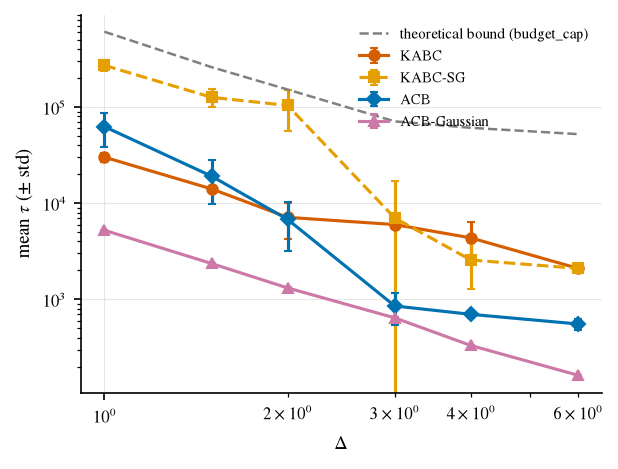

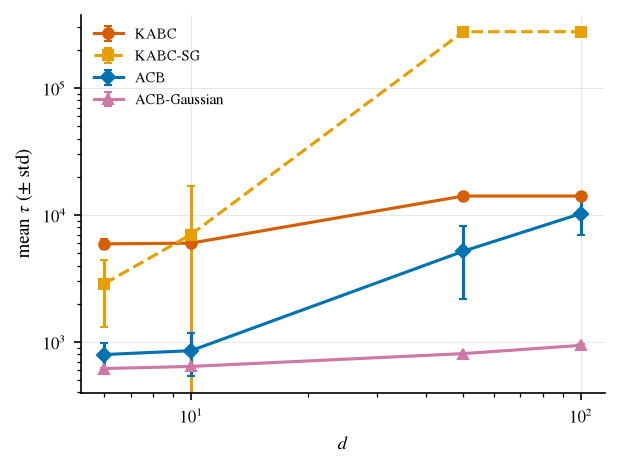

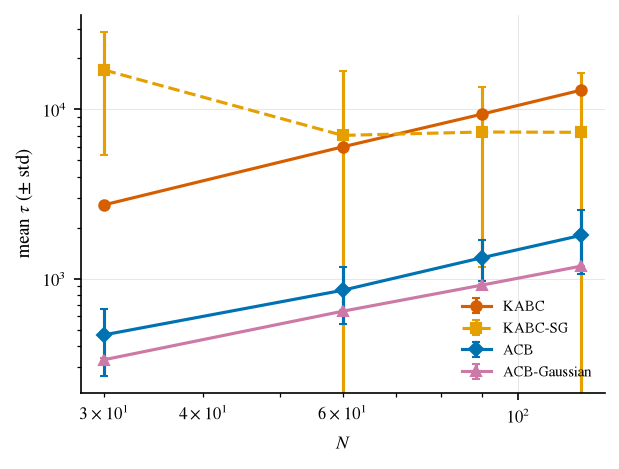

In [2]:
def budget_vs_param_plot(swept_param, xlabel, fig_name, overlay_theory=False):
    sub = df[df["swept_param"] == swept_param]
    fig, ax = plt.subplots(figsize=(4.2, 3.2))
    for algo in BASE_ALGOS:
        g = (sub[sub["algorithm"] == algo].groupby("swept_value")["tau"]
             .agg(["mean", "std"]).reset_index().sort_values("swept_value"))
        ax.errorbar(g["swept_value"], g["mean"], yerr=g["std"], capsize=2, **style_for(algo))
    if overlay_theory:
        # Restrict to BASE_ALGOS rows: the "budget_cap" column stores each
        # row's OWN used budget cap, and for the 5 derived -0.5x/unif-kkm
        # rows that is a reduced value (min(multiplier * base tau, cap)),
        # not the grid point's true formula-based bound. Averaging over all
        # 8 rows would deflate this line well below the real theoretical
        # bound; only the 3 base rows carry the true, undivided value.
        theory = (sub[sub["algorithm"].isin(BASE_ALGOS)].groupby("swept_value")["budget_cap"]
                  .mean().reset_index().sort_values("swept_value"))
        ax.plot(theory["swept_value"], theory["budget_cap"], linestyle="--", color="grey",
                linewidth=1.2, label="theoretical bound (budget_cap)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"mean $\tau$ (± std)")
    ax.legend(fontsize=7, frameon=False)
    fig.tight_layout()
    savefig(fig, fig_name, fig_dir="../results/figures")
    plt.show()


budget_vs_param_plot("Delta", r"$\Delta$", "exp1_fig1_tau_vs_delta", overlay_theory=True)
budget_vs_param_plot("d", "$d$", "exp1_fig2_tau_vs_d")
budget_vs_param_plot("N", "$N$", "exp1_fig2b_tau_vs_N")


## Figure 2: convergence rate vs. sweep parameter — kabc/kabc-sg/acb only

Fraction of reps with `stopped=True`, mean ± std across reps (a Bernoulli mean ± its std). One block per grid point (sweep value), 4 bars per block (kabc/kabc-sg/acb/acb-gaussian) — mirrors Experiment 3's convergence-rate plot. Read alongside Figure 1: a method that never converges reports its graceful trivial-cluster fallback (ARI exactly 0.0, per the same mathematical property documented for Experiment 3/4), not a real clustering attempt.


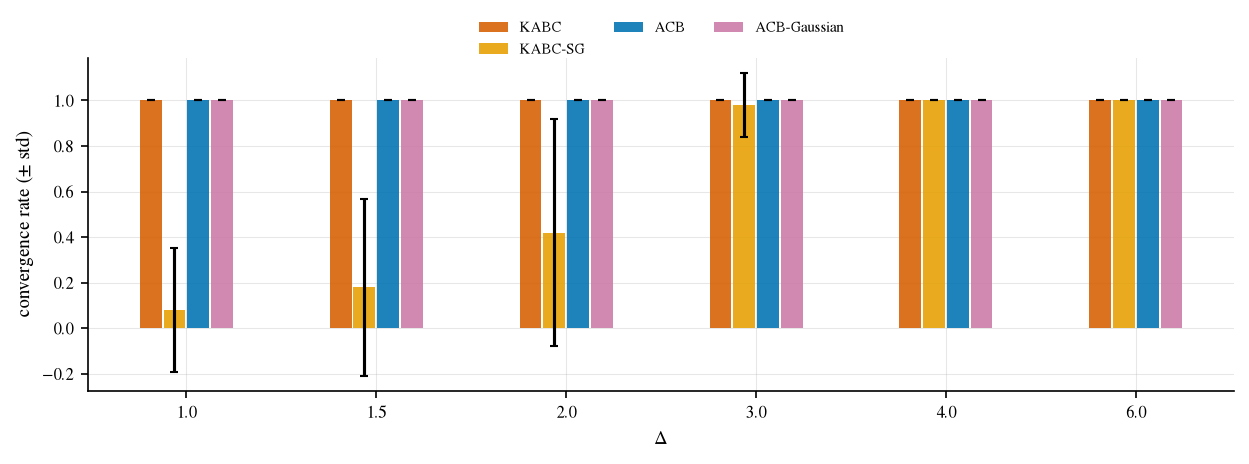

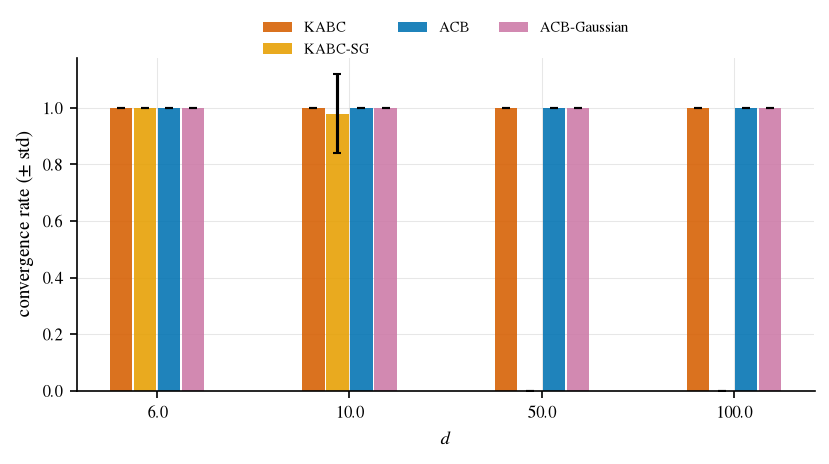

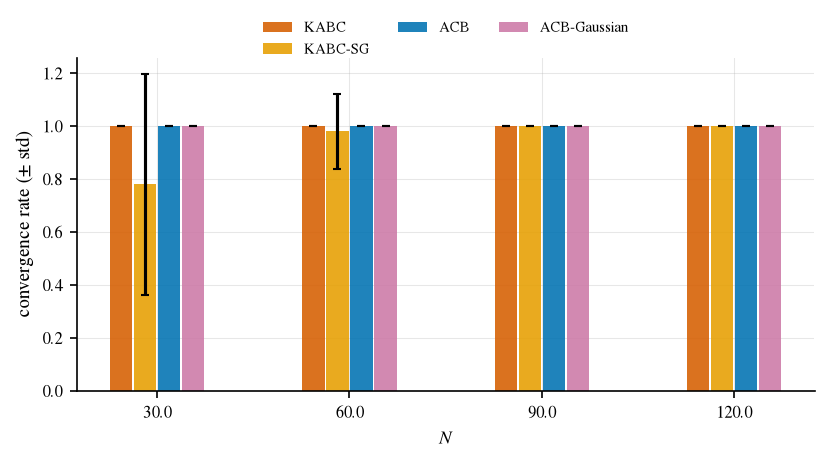

In [3]:
def convergence_bar_plot(swept_param, xlabel, fig_name):
    sub = df[df["swept_param"] == swept_param]
    values = sorted(sub["swept_value"].unique())
    n_algo = len(BASE_ALGOS)
    bar_width = 0.8 / n_algo
    group_gap = 0.6

    fig, ax = plt.subplots(figsize=(max(4.0, len(values) * 1.4), 3.2))
    xtick_positions, xtick_labels = [], []
    for v_idx, value in enumerate(values):
        group_center = v_idx * (1.0 + group_gap)
        for a_idx, algo in enumerate(BASE_ALGOS):
            s = sub[(sub["swept_value"] == value) & (sub["algorithm"] == algo)]["stopped"]
            x = group_center + (a_idx - (n_algo - 1) / 2) * bar_width
            ax.bar(x, s.mean(), yerr=s.std(), width=bar_width * 0.92, capsize=2,
                   color=ALGO_COLORS[algo], alpha=0.88,
                   label=ALGO_LABELS[algo] if v_idx == 0 else None)
        xtick_positions.append(group_center)
        xtick_labels.append(str(value))

    ax.set_xticks(xtick_positions)
    ax.set_xticklabels(xtick_labels, fontsize=8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("convergence rate (± std)")
    ax.legend(fontsize=7, frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.15))
    fig.tight_layout()
    savefig(fig, fig_name, fig_dir="../results/figures")
    plt.show()


convergence_bar_plot("Delta", r"$\Delta$", "exp1_fig3_convergence_vs_delta")
convergence_bar_plot("d", "$d$", "exp1_fig3b_convergence_vs_d")
convergence_bar_plot("N", "$N$", "exp1_fig3c_convergence_vs_N")


## Figure 3: ARI vs. sweep parameter — all 8 algorithm rows

Mean ± std over reps, all 8 rows together. This is where the `-0.5x` rows earn their keep: a SMALL ARI drop from a base algorithm to its own `-0.5x` variant means that algorithm's stopping rule needed little of its own margin (the bound is comfortably tight relative to what was actually necessary); a LARGE drop means real accuracy was still being bought in that last half of budget (the bound is conservative). `unif-kkm-1x`/`unif-kkm-0.5x` sitting close to `kabc`/`kabc-0.5x` would suggest active/adaptive selection isn't earning much of an edge at that matched budget; a gap suggests it is.


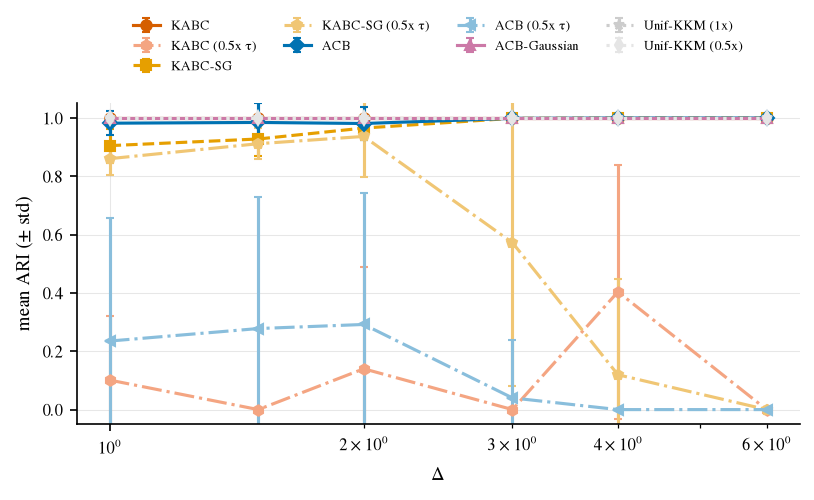

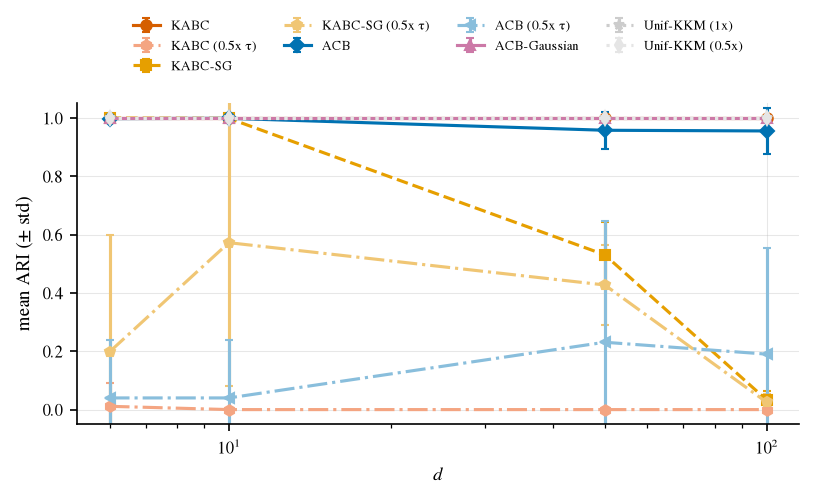

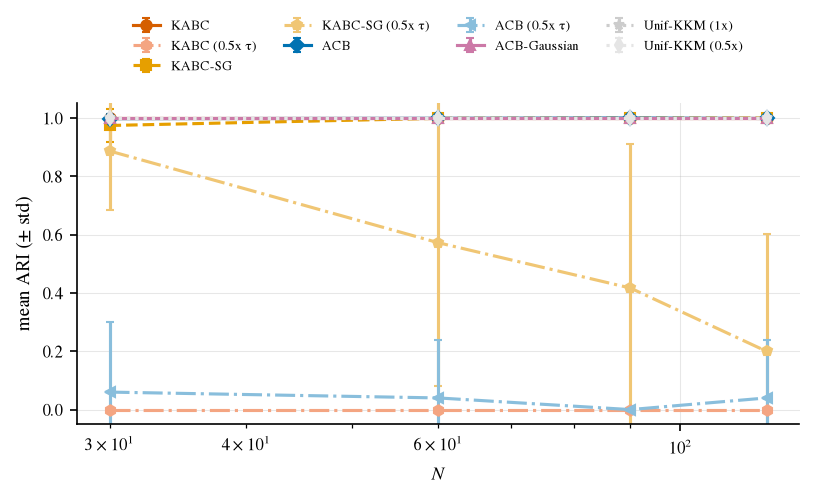

In [4]:
def ari_vs_param_plot(swept_param, xlabel, fig_name):
    sub = df[df["swept_param"] == swept_param]
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    for algo in ALL_ALGOS:
        g = (sub[sub["algorithm"] == algo].groupby("swept_value")["ari"]
             .agg(["mean", "std"]).reset_index().sort_values("swept_value"))
        ax.errorbar(g["swept_value"], g["mean"], yerr=g["std"], capsize=2, **style_for(algo))
    ax.set_xscale("log")
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("mean ARI (± std)")
    ax.legend(fontsize=6.5, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.3))
    fig.tight_layout()
    savefig(fig, fig_name, fig_dir="../results/figures")
    plt.show()


ari_vs_param_plot("Delta", r"$\Delta$", "exp1_fig4_ari_vs_delta")
ari_vs_param_plot("d", "$d$", "exp1_fig4b_ari_vs_d")
ari_vs_param_plot("N", "$N$", "exp1_fig4c_ari_vs_N")


## Summary tables: exact mean ± std per algorithm, per sweep

Printed (not just plotted), one table per sweep (rows = sweep value × algorithm), same convention as notebooks 03/04's summary tables. `frac_stopped`/`std_stopped` are the same convergence-rate quantity as Figure 2, in table form, for all 8 algorithms (not just the 3 shown in Figure 2's bars).


In [5]:
for swept_param, _, _ in SWEEPS:
    sub = df[df["swept_param"] == swept_param]
    summary = (
        sub.groupby(["swept_value", "algorithm"])
        .agg(
            mean_tau=("tau", "mean"), std_tau=("tau", "std"),
            mean_ari=("ari", "mean"), std_ari=("ari", "std"),
            frac_stopped=("stopped", "mean"), std_stopped=("stopped", "std"),
        )
        .reset_index()
    )
    summary["algorithm"] = pd.Categorical(summary["algorithm"], categories=ALL_ALGOS, ordered=True)
    summary = summary.sort_values(["swept_value", "algorithm"])
    print(f"=== sweep: {swept_param} ===")
    display(summary)


=== sweep: Delta ===


,swept_value,algorithm,mean_tau,std_tau,mean_ari,std_ari,frac_stopped,std_stopped
3,1.0,kabc,30170.40,3313.660631,1.000000,0.000000,1.00,0.000000
4,1.0,kabc-0.5x,13776.00,1603.384176,0.101333,0.218479,0.00,0.000000
5,1.0,kabc-sg,272173.20,37241.899952,0.905316,0.057964,0.08,0.274048
6,1.0,kabc-sg-0.5x,132537.60,18260.325517,0.860624,0.057440,0.00,0.000000
0,1.0,acb,62696.84,24161.806657,0.982346,0.041559,1.00,0.000000
1,1.0,acb-0.5x,29875.48,11296.933149,0.235056,0.423404,0.24,0.431419
2,1.0,acb-gaussian,5237.46,62.880908,1.000000,0.000000,1.00,0.000000
8,1.0,unif-kkm-1x,30170.40,3313.660631,1.000000,0.000000,1.00,0.000000
7,1.0,unif-kkm-0.5x,15084.00,1662.768775,1.000000,0.000000,1.00,0.000000
12,1.5,kabc,14100.00,0.000000,1.000000,0.000000,1.00,0.000000


=== sweep: d ===


,swept_value,algorithm,mean_tau,std_tau,mean_ari,std_ari,frac_stopped,std_stopped
3,6.0,kabc,5922.00,551.543289,1.000000,0.000000,1.00,0.000000
4,6.0,kabc-0.5x,2064.00,254.558441,0.011259,0.079615,0.00,0.000000
5,6.0,kabc-sg,2880.00,1575.837970,1.000000,0.000000,1.00,0.000000
6,6.0,kabc-sg-0.5x,660.00,727.309832,0.198034,0.400156,0.14,0.350510
0,6.0,acb,796.12,187.294992,0.998037,0.013881,1.00,0.000000
1,6.0,acb-0.5x,393.92,85.340098,0.040000,0.197949,0.04,0.197949
2,6.0,acb-gaussian,617.76,6.923960,1.000000,0.000000,1.00,0.000000
8,6.0,unif-kkm-1x,5922.00,551.543289,1.000000,0.000000,1.00,0.000000
7,6.0,unif-kkm-0.5x,2960.40,280.014285,1.000000,0.000000,1.00,0.000000
12,10.0,kabc,6000.00,0.000000,1.000000,0.000000,1.00,0.000000


=== sweep: N ===


,swept_value,algorithm,mean_tau,std_tau,mean_ari,std_ari,frac_stopped,std_stopped
3,30.0,kabc,2730.00,0.000000,1.000000,0.000000,1.00,0.000000
4,30.0,kabc-0.5x,960.00,0.000000,0.000000,0.000000,0.00,0.000000
5,30.0,kabc-sg,17050.20,11673.355234,0.974469,0.056984,0.78,0.418452
6,30.0,kabc-sg-0.5x,5875.20,5260.530058,0.887010,0.201904,0.40,0.494872
0,30.0,acb,465.84,199.699709,0.997963,0.014401,1.00,0.000000
1,30.0,acb-0.5x,222.72,70.286597,0.060000,0.239898,0.06,0.239898
2,30.0,acb-gaussian,332.22,8.076901,1.000000,0.000000,1.00,0.000000
8,30.0,unif-kkm-1x,2730.00,0.000000,1.000000,0.000000,1.00,0.000000
7,30.0,unif-kkm-0.5x,1350.00,0.000000,1.000000,0.000000,1.00,0.000000
12,60.0,kabc,6000.00,0.000000,1.000000,0.000000,1.00,0.000000
